# Breast Cancer Classification

**Objective:** Build machine learning models that classify breast tumor samples as **benign** or **malignant** from cell nucleus measurements.

**Tools:** Python · Pandas · Scikit-learn · Matplotlib · Seaborn

**Workflow**
1. Load the Breast Cancer Wisconsin (Diagnostic) dataset
2. Explore the data and check for missing values
3. Split into 80% training / 20% testing (stratified)
4. Train Logistic Regression and Random Forest models
5. Evaluate with accuracy, confusion matrix, and classification report
6. Compare the models and visualize the results

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score,
                             roc_curve, roc_auc_score)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load the dataset

In [3]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target  # 0 = malignant, 1 = benign

print("Shape:", df.shape)
print("Classes:", dict(enumerate(data.target_names)))
df.head()

Shape: (569, 31)
Classes: {0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 2. Explore the data

The dataset has 569 samples and 30 numeric features computed from digitized images of fine-needle aspirates. Each feature describes a property of the cell nuclei (radius, texture, perimeter, area, smoothness, etc.) as a *mean*, *standard error*, and *worst* (largest) value.

In [4]:
print("Missing values in the whole dataset:", df.isnull().sum().sum())
print()
df.info()

Missing values in the whole dataset: 0

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 1

In [5]:
df.describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
mean radius,14.127,3.524,6.981,28.110
mean texture,19.290,4.301,9.710,39.280
mean perimeter,91.969,24.299,43.790,188.500
mean area,654.889,351.914,143.500,2501.000
mean smoothness,0.096,0.014,0.053,0.163
mean compactness,0.104,0.053,0.019,0.345
mean concavity,0.089,0.080,0.000,0.427
mean concave points,0.049,0.039,0.000,0.201
mean symmetry,0.181,0.027,0.106,0.304
mean fractal dimension,0.063,0.007,0.050,0.097


### Class balance

target
benign       357
malignant    212
Name: count, dtype: int64

target
benign       62.7%
malignant    37.3%
Name: count, dtype: str


C:\Users\GIGA BYIT\AppData\Local\Temp\ipykernel_12748\1087136835.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df["target"].map({0: "malignant", 1: "benign"}),


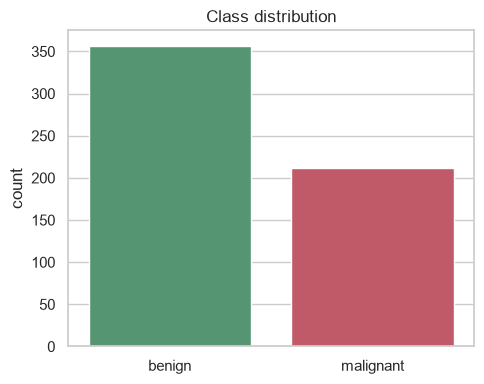

In [6]:
counts = df["target"].map({0: "malignant", 1: "benign"}).value_counts()
print(counts)
print()
print((counts / len(df) * 100).round(1).astype(str) + "%")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=df["target"].map({0: "malignant", 1: "benign"}),
              order=["benign", "malignant"], palette=["#4C9F70", "#D1495B"], ax=ax)
ax.set_title("Class distribution")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

The classes are moderately imbalanced (about 63% benign, 37% malignant), so the split below is **stratified** to keep the same ratio in both sets, and we look beyond accuracy at precision and recall.

### Which features separate the classes?

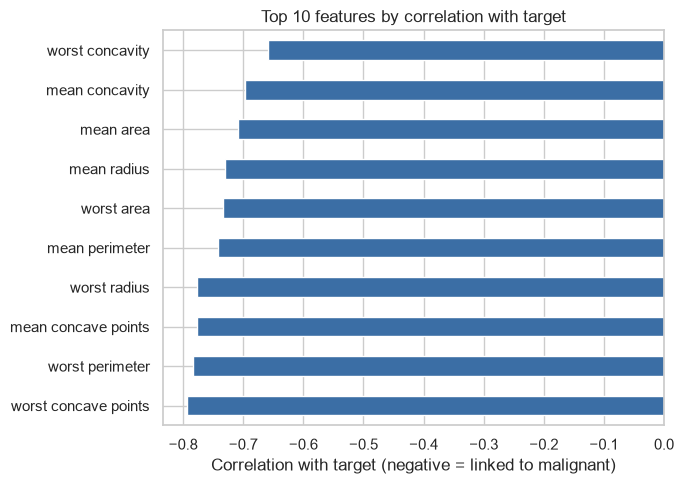

In [7]:
corr = df.corr()["target"].drop("target").sort_values()
top = corr.abs().sort_values(ascending=False).head(10).index

fig, ax = plt.subplots(figsize=(7, 5))
corr[top].sort_values().plot(kind="barh", color="#3B6EA5", ax=ax)
ax.set_title("Top 10 features by correlation with target")
ax.set_xlabel("Correlation with target (negative = linked to malignant)")
plt.tight_layout()
plt.show()

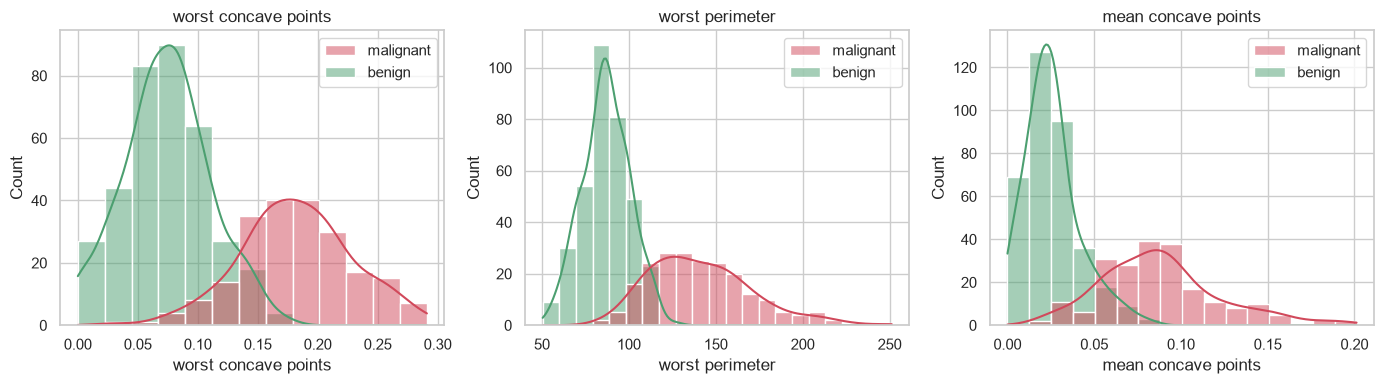

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, feat in zip(axes, ["worst concave points", "worst perimeter", "mean concave points"]):
    sns.histplot(data=df, x=feat, hue=df["target"].map({0: "malignant", 1: "benign"}),
                 kde=True, palette={"benign": "#4C9F70", "malignant": "#D1495B"}, ax=ax)
    ax.set_title(feat)
    ax.get_legend().set_title("")
plt.tight_layout()
plt.show()

Malignant tumors tend to have larger, more irregular nuclei: higher perimeter, area, and concavity values. Several features are strongly correlated with each other (radius, perimeter, and area are almost redundant), which matters for linear models but not for tree ensembles.

## 3. Train/test split (80/20)

In [9]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (455, 30)  Test: (114, 30)


## 4. Train the models

- **Logistic Regression** is wrapped in a pipeline with `StandardScaler`, because the features are on very different scales (e.g. area in the hundreds vs. smoothness below 0.2). The scaler is fit only on the training data inside the pipeline, which avoids leaking test information.
- **Random Forest** doesn't need scaling, since tree splits are scale-invariant.

In [10]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    ),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Random Forest


## 5. Evaluate the models

In [11]:
results = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    results[name] = {"y_pred": y_pred, "y_proba": y_proba}

    print("=" * 55)
    print(name)
    print("=" * 55)
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
    print(classification_report(y_test, y_pred, target_names=data.target_names, digits=3))

Logistic Regression
Accuracy: 0.9825

              precision    recall  f1-score   support

   malignant      0.976     0.976     0.976        42
      benign      0.986     0.986     0.986        72

    accuracy                          0.982       114
   macro avg      0.981     0.981     0.981       114
weighted avg      0.982     0.982     0.982       114

Random Forest
Accuracy: 0.9561

              precision    recall  f1-score   support

   malignant      0.951     0.929     0.940        42
      benign      0.959     0.972     0.966        72

    accuracy                          0.956       114
   macro avg      0.955     0.950     0.953       114
weighted avg      0.956     0.956     0.956       114



### Confusion matrices

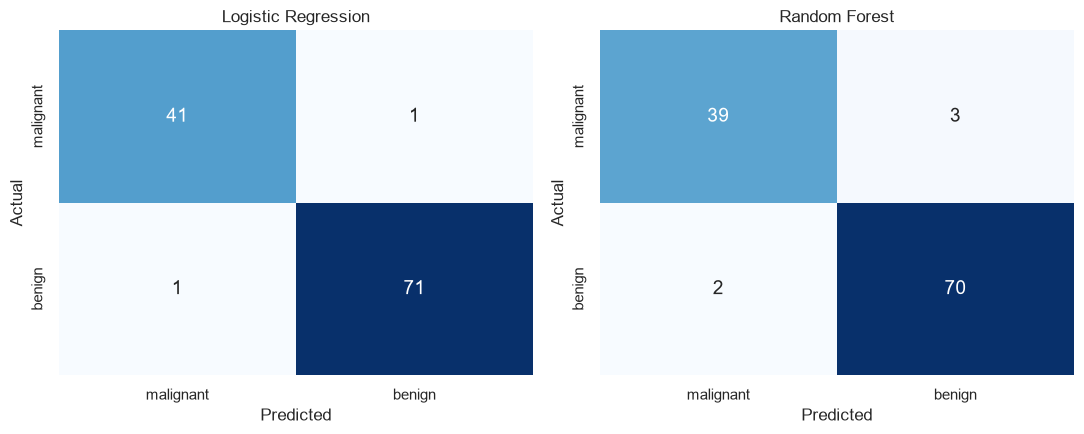

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, res) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, res["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=data.target_names, yticklabels=data.target_names,
                annot_kws={"size": 14})
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In a medical setting the two error types are not equally costly. A **malignant tumor predicted as benign** (false negative for cancer) is the dangerous mistake, so the **recall on the malignant class** is the most important number in the reports above.

## 6. Compare the models

In [13]:
rows = []
for name, res in results.items():
    y_pred = res["y_pred"]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        # pos_label=0 -> metrics for the malignant class
        "Precision (malignant)": precision_score(y_test, y_pred, pos_label=0),
        "Recall (malignant)": recall_score(y_test, y_pred, pos_label=0),
        "F1 (malignant)": f1_score(y_test, y_pred, pos_label=0),
        "ROC AUC": roc_auc_score(y_test, res["y_proba"]),
    })

comparison = pd.DataFrame(rows).set_index("Model").round(4)
comparison

,Accuracy,Precision (malignant),Recall (malignant),F1 (malignant),ROC AUC
Model,,,,,
Logistic Regression,0.9825,0.9762,0.9762,0.9762,0.9954
Random Forest,0.9561,0.9512,0.9286,0.9398,0.9931


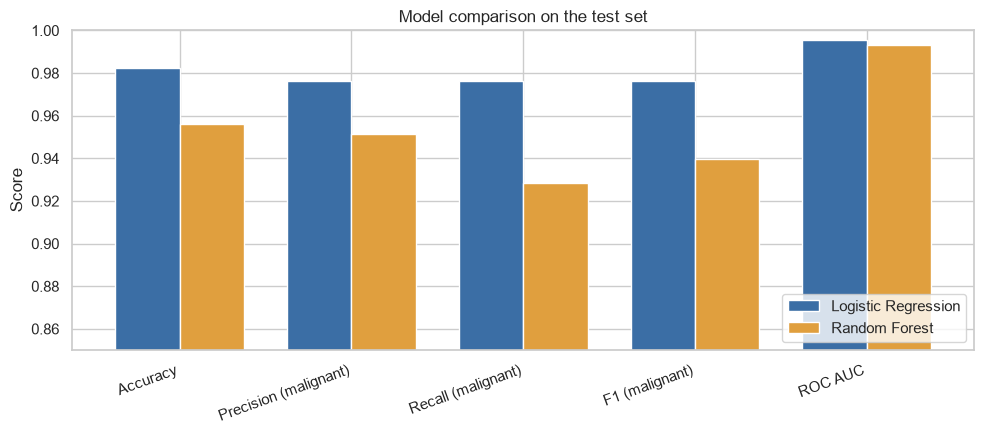

In [14]:
ax = comparison.T.plot(kind="bar", figsize=(10, 4.5), color=["#3B6EA5", "#E09F3E"], width=0.75)
ax.set_ylim(0.85, 1.0)
ax.set_title("Model comparison on the test set")
ax.set_ylabel("Score")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### ROC curves

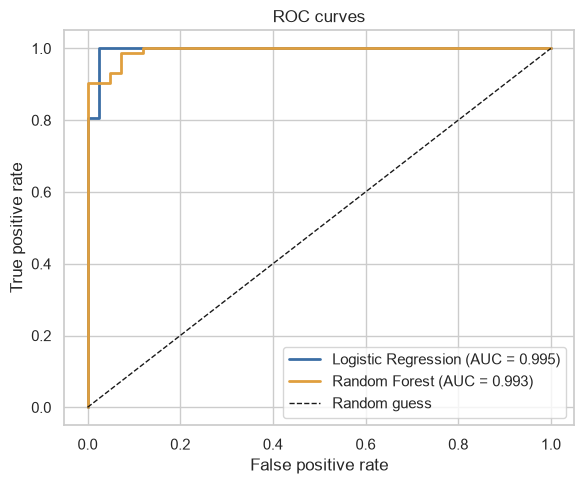

In [15]:
fig, ax = plt.subplots(figsize=(6, 5))
for (name, res), color in zip(results.items(), ["#3B6EA5", "#E09F3E"]):
    fpr, tpr, _ = roc_curve(y_test, res["y_proba"])
    ax.plot(fpr, tpr, color=color, lw=2,
            label=f"{name} (AUC = {roc_auc_score(y_test, res['y_proba']):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Random Forest feature importance

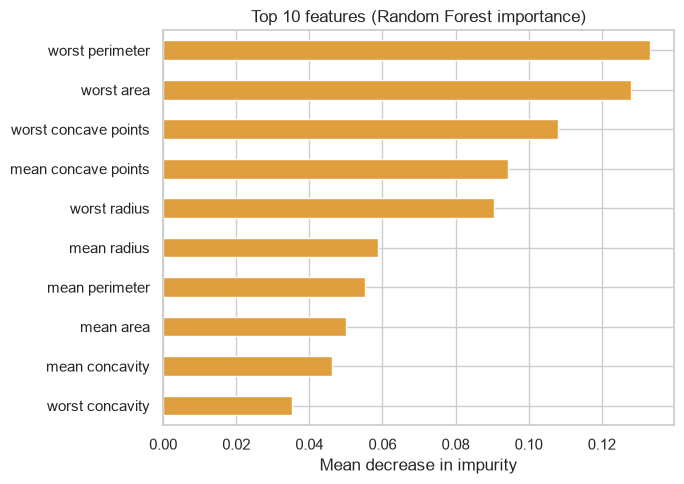

In [16]:
importances = pd.Series(models["Random Forest"].feature_importances_, index=X.columns)
fig, ax = plt.subplots(figsize=(7, 5))
importances.sort_values().tail(10).plot(kind="barh", color="#E09F3E", ax=ax)
ax.set_title("Top 10 features (Random Forest importance)")
ax.set_xlabel("Mean decrease in impurity")
plt.tight_layout()
plt.show()

## Conclusion

| Model | Accuracy | Malignant recall | Malignant precision | ROC AUC |
|---|---|---|---|---|
| Logistic Regression | **98.2%** | **97.6%** (41 / 42) | **97.6%** | **0.995** |
| Random Forest | 95.6% | 92.9% (39 / 42) | 95.1% | 0.993 |

- **Logistic Regression performed best** on this test set. It missed only 1 of the 42 malignant tumors, compared with 3 for the Random Forest, and that is the error that matters most clinically.
- Both models rank samples almost perfectly (ROC AUC above 0.99), so most of the difference comes from where the default 0.5 decision threshold falls.
- The data is close to linearly separable once the features are standardized, which explains why a simple, interpretable linear model beats the more complex ensemble here.
- The Random Forest's most important features (worst concave points, worst perimeter, worst area, etc.) match the features most correlated with the target in the exploratory analysis, which is a good consistency check.
